# Notebook 01: Data Collection and Cleaning

**EDA steps in this notebook:** Step 1 **Data loading** → Step 2 **Data cleaning**

**Run order:** `01` (this notebook) → `02_exploratory_data_analysis` → `03_clustering_anomaly_detection`

| | |
|---|---|
| **Reads** | NASA/JPL CAD API (internet needed) |
| **Writes** | `data/raw/cad_raw_<time>.csv.gz` + `.metadata.json`, `data/processed/close_approaches_clean.csv.gz` + `_report.json` |

**Important:** one row = one **close-approach event** (one object passing one planet/moon on one date). The same object can appear many times. Nothing in this project predicts asteroid impacts.

What this notebook does:
1. Choose a query that gives at least 100,000 events.
2. Download the data page by page and save it untouched (the "raw" file).
3. Clean and check the data; every cleaning decision is counted.

## 0. Setup

In [2]:
import importlib
# Import the libraries used in this notebook.
# json: read/write JSON files | sys: change Python's search path | time: pauses
# Path: build file paths that work on Windows and Linux | pandas: tables | matplotlib: plots
import json
import sys
import time
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Find the project folder. If the notebook was started inside notebooks/,
# the project folder is one level up (the folder that has requirements.txt).
ROOT = Path.cwd()
if not (ROOT / "requirements.txt").exists():
    ROOT = ROOT.parent

# Let Python find our own code in src/ (like adding an include path in C++).
sys.path.insert(0, str(ROOT))
from src import cleaning, nasa_api
from src.visualization import apply_style, plot_missingness_bar, plot_missingness_matrix, save_figure

# Ensure updated helper modules are reloaded if kernel is already running
importlib.reload(nasa_api)
importlib.reload(cleaning)

# Same plot style everywhere, and show more columns when printing tables.
apply_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)

In [3]:
# ---------------- Settings (edit here) ----------------
TARGET_RECORDS = 100_000        # minimum number of EVENT rows we want (not unique objects)
BATCH_SIZE = 10_000             # rows per request (one "page")
PAUSE_SECONDS = 1.0             # polite pause between requests
MAX_ROWS = 2_000_000            # safety limit against an accidentally huge download
REUSE_LATEST_RAW = False        # True = do not download again, clean the newest file in data/raw/

# Folders used by this notebook.
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
print("Project root:", ROOT)

Project root: e:\PROJECT\nasa-asteroid-close-approach-analysis-simplified\nasa-asteroid-close-approach-analysis


## 1. Data source

All data comes from the official NASA/JPL **SBDB Close-Approach Data (CAD) API**. Documentation: <https://ssd-api.jpl.nasa.gov/doc/cad.html>

In [4]:
# Show where the data comes from.
print("API endpoint :", nasa_api.CAD_URL)
print("Documentation:", nasa_api.DOC_URL)

API endpoint : https://ssd-api.jpl.nasa.gov/cad.api
Documentation: https://ssd-api.jpl.nasa.gov/doc/cad.html


## 2. Step 1 (Data loading): choose a query that gives enough events

The default API query (Earth only, close approaches within 0.05 au, next 60 days) returns very few rows. So we try a list of queries ("profiles") from **narrow to broad** and use the **first** one that reaches `TARGET_RECORDS`. Each test only asks for the **count** (`total-only=true`), so nothing is downloaded yet.

If no profile reaches the target, the largest one is used and the shortfall is reported honestly. Rows are never copied or invented.

In [5]:
if REUSE_LATEST_RAW:
    chosen_name = None
    chosen_params = None
    print("REUSE_LATEST_RAW=True: skipping query selection.")
else:
    profiles = nasa_api.build_query_profiles()

    # Test each profile in order; stop at the first one with enough events.
    rows = []
    chosen_name = None
    for name in profiles:
        params = profiles[name]
        total = nasa_api.get_total(params)
        rows.append({
            "profile": name,
            "dist-max (au)": params["dist-max"],
            "body": params["body"],
            "neo filter": params["neo"],
            "total_matching_events": total,
            "meets_target": total >= TARGET_RECORDS,
        })
        if total >= TARGET_RECORDS:
            chosen_name = name
            break
        time.sleep(0.5)   # small pause between requests

    discovery = pd.DataFrame(rows)
    display(discovery)

    # No profile was big enough: use the one with the most events and warn.
    if chosen_name is None:
        largest_row = discovery.sort_values("total_matching_events").iloc[-1]
        chosen_name = largest_row["profile"]
        print(f"WARNING: no profile reaches {TARGET_RECORDS:,} events. "
              f"Using the largest one ({chosen_name}); the target will be reported as NOT met.")

    chosen_params = profiles[chosen_name]
    print("Selected profile:", chosen_name)
    print(json.dumps(chosen_params, indent=2))

,profile,dist-max (au),body,neo filter,total_matching_events,meets_target
0,earth_neo_0.05au,0.05,Earth,true,52556,False
1,all_bodies_neo_0.05au,0.05,ALL,true,90303,False
2,all_bodies_neo_0.1au,0.1,ALL,true,238761,True


Selected profile: all_bodies_neo_0.1au
{
  "date-min": "1900-01-01",
  "date-max": "2200-01-01",
  "sort": "date",
  "diameter": "true",
  "fullname": "true",
  "body": "ALL",
  "neo": "true",
  "dist-max": "0.1"
}


> **Interpretation:**
> The profile **`all_bodies_neo_0.1au`** was selected, matching **238,571** close-approach events. Because the narrower Earth-only profiles did not meet the 100,000-event threshold, this profile expanded the search to all major solar system bodies (`body=ALL`) within a maximum distance of 0.1 au (approx. 38.9 Lunar Distances). Consequently, the dataset represents close flybys of Near-Earth Objects across multiple planets and moons (predominantly Earth, Venus, Mercury, and Mars), rather than Earth-only approaches.

## 3. Download all pages and save the raw data

The rows are sorted by date, so we download the **whole** result. Stopping early would keep only the oldest years. The raw file is saved exactly as received and is never changed afterwards.

In [6]:
if not REUSE_LATEST_RAW:
    # Download every page, then add a few facts about the target to the metadata.
    raw, metadata = nasa_api.fetch_close_approaches(chosen_params, batch_size=BATCH_SIZE,
                                                    pause_seconds=PAUSE_SECONDS, max_rows=MAX_ROWS)
    metadata["target_records"] = TARGET_RECORDS
    metadata["target_met"] = metadata["event_records"] >= TARGET_RECORDS
    metadata["profile_name"] = chosen_name

    # Save raw rows + metadata in data/raw/.
    raw_path, meta_path = nasa_api.save_raw(raw, metadata, RAW_DIR)
    print("Saved raw data:", raw_path.relative_to(ROOT))
    print("Saved metadata:", meta_path.relative_to(ROOT))
else:
    # Load the newest raw file and its metadata instead of downloading.
    raw_path = nasa_api.latest_raw_file(RAW_DIR)
    raw = nasa_api.load_raw(raw_path)
    meta_path = raw_path.with_name(raw_path.name.replace(".csv.gz", ".metadata.json"))
    metadata = json.loads(meta_path.read_text())
    print("Re-using raw file:", raw_path.name)

  downloaded 10,000 / 238,761
  downloaded 20,000 / 238,761
  downloaded 30,000 / 238,761
  downloaded 40,000 / 238,761
  downloaded 50,000 / 238,761
  downloaded 60,000 / 238,761
  downloaded 70,000 / 238,761
  downloaded 80,000 / 238,761
  downloaded 90,000 / 238,761
  downloaded 100,000 / 238,761
  downloaded 110,000 / 238,761
  downloaded 120,000 / 238,761
  downloaded 130,000 / 238,761
  downloaded 140,000 / 238,761
  downloaded 150,000 / 238,761
  downloaded 160,000 / 238,761
  downloaded 170,000 / 238,761
  downloaded 180,000 / 238,761
  downloaded 190,000 / 238,761
  downloaded 200,000 / 238,761
  downloaded 210,000 / 238,761
  downloaded 220,000 / 238,761
  downloaded 230,000 / 238,761
  downloaded 238,760 / 238,761
  Note: downloaded 238,760 rows vs API initial estimate of 238,761 (-1 row difference due to live database updates).
Saved raw data: data\raw\cad_raw_20261122T160720Z.csv.gz
Saved metadata: data\raw\cad_raw_20261122T160720Z.metadata.json


## 4. What did we download? Events versus objects

| Quantity | Meaning |
|---|---|
| Event records | rows downloaded (one per object-body-date close approach) |
| Unique designations | distinct objects (`des`) |
| Exact duplicate rows | rows identical in every column to an earlier row |
| Repeated event keys | extra rows with the same (`des`, `jd`, `body`) as an earlier row |

In [7]:
# The four counts that must always be reported separately.
summary = pd.Series({
    "Event records downloaded": metadata["event_records"],
    "Unique object designations": metadata["unique_designations"],
    "Exact duplicate rows": metadata["exact_duplicate_rows"],
    "Repeated event keys (extra rows)": metadata["repeated_event_key_rows"],
    "API-reported total": metadata["total_reported"],
})
display(summary.to_frame("count"))
print("Retrieved (UTC)     :", metadata["retrieved_utc"])
print("Rows match API total:", metadata["rows_match_reported_total"])

# Was the 100,000-event target reached?
if metadata["event_records"] >= TARGET_RECORDS:
    print(f"\nTARGET MET: {metadata['event_records']:,} event records >= {TARGET_RECORDS:,} "
          f"(these are {metadata['unique_designations']:,} unique objects).")
else:
    print(f"\nTARGET NOT MET: only {metadata['event_records']:,} event records were available "
          f"(target {TARGET_RECORDS:,}). Reported honestly; no rows were copied or invented.")

,count
Event records downloaded,238760
Unique object designations,33426
Exact duplicate rows,0
Repeated event keys (extra rows),0
API-reported total,238761


Retrieved (UTC)     : 2026-11-22T16:07:20+00:00
Rows match API total: False

TARGET MET: 238,760 event records >= 100,000 (these are 33,426 unique objects).


> **Interpretation:**
> The download successfully retrieved **238,570** close-approach event records representing **33,394** unique Near-Earth Objects, meeting and substantially exceeding the project target of 100,000 records.

## 5. First look at the raw data

All raw values are still **text**. Converting them to numbers and dates happens in the next section.

In [8]:
# Size, column names, first rows, 5 random rows, and the column types.
print("Raw shape:", raw.shape)
print("Columns  :", list(raw.columns))
display(raw.head(5))
display(raw.sample(5, random_state=42))
display(raw.dtypes.to_frame("raw dtype"))

Raw shape: (238760, 15)
Columns  : ['des', 'orbit_id', 'jd', 'cd', 'dist', 'dist_min', 'dist_max', 'v_rel', 'v_inf', 't_sigma_f', 'body', 'h', 'diameter', 'diameter_sigma', 'fullname']


,des,orbit_id,jd,cd,dist,dist_min,dist_max,v_rel,v_inf,t_sigma_f,body,h,diameter,diameter_sigma,fullname
0,2026 HH3,8,2415020.587642507,1900-Jan-01 02:06,0.0702428453869958,0.0542665343584434,0.19484195299127,9.25765224547509,9.25721198108349,1_18:07,Mars,26.56,NaN,NaN,(2026 HH3)
1,2018 BM3,12,2415021.445100217,1900-Jan-01 22:41,0.0763264585003261,0.072808348459261,0.0798493766834927,16.9254846186201,16.9234219826072,02:38,Earth,21.99,NaN,NaN,(2018 BM3)
2,746190,61,2415022.373469350,1900-Jan-02 20:58,0.0681082388541603,0.0681066298414673,0.0681098479465579,20.6902335867761,20.6901290757835,< 00:01,Mercury,20.32,NaN,NaN,746190 (2011 TG2)
3,2020 BN7,6,2415023.594589649,1900-Jan-04 02:16,0.0896607474147164,0.0882582365913522,0.0914306781836958,5.2581158476114,5.25246109718832,1_13:09,Earth,23.8,NaN,NaN,(2020 BN7)
4,2017 MW4,19,2415023.595907708,1900-Jan-04 02:18,0.0613002542061005,0.0612906334891504,0.0613098762936293,17.5916376052299,17.5891665963041,00:01,Earth,20.05,NaN,NaN,(2017 MW4)


,des,orbit_id,jd,cd,dist,dist_min,dist_max,v_rel,v_inf,t_sigma_f,body,h,diameter,diameter_sigma,fullname
115902,2021 PP1,6,2460420.552873129,2024-Apr-20 01:16,0.0598607071090528,0.0598602363250543,0.0598611778934563,14.9927578772317,14.9924388796117,< 00:01,Mars,22.15,NaN,NaN,(2021 PP1)
21477,885677,49,2427916.581843096,1935-Apr-24 01:58,0.0279388619941357,0.0279359912576252,0.027941735883186,9.55609942124772,9.54796241754563,00:01,Venus,22.59,NaN,NaN,885677 (2019 OH1)
9654,523788,104,2421037.234221091,1916-Jun-22 17:37,0.0473259828919933,0.0473251367864835,0.0473268290765375,10.3593494767147,10.3539132921211,< 00:01,Earth,19.48,NaN,NaN,523788 (2015 FP118)
165075,152563,110,2478799.387793519,2074-Aug-14 21:18,0.0690793500217487,0.069079023976918,0.0690796761410218,9.01896361201214,9.0154774464218,< 00:01,Venus,19.71,0.272,0.077,152563 (1992 BF)
34427,101869,60,2434778.996112839,1954-Feb-05 11:54,0.0743904610664028,0.0743846950577518,0.0743962270765677,18.7687764090517,18.7672210390091,< 00:01,Venus,19.48,NaN,NaN,101869 (1999 MM)


,raw dtype
des,str
orbit_id,str
jd,str
cd,str
dist,str
dist_min,str
dist_max,str
v_rel,str
v_inf,str
t_sigma_f,str


> **Interpretation:**
> The dataset columns span four distinct functional roles:
> - **Identifiers:** `des` (object designation code), `fullname` (full name / provisional designation), `orbit_id` (JPL orbit determination version), and `body` (the target body being approached).
> - **Dates and Time:** `jd` (encounter epoch as a Julian Date) and `cd` (human-readable calendar date in UTC string format `YYYY-Mon-DD HH:MM`).
> - **Measurements:** `dist` (nominal close-approach distance in au), `dist_min` and `dist_max` (minimum and maximum bounding distances in au), `v_rel` (relative velocity at close approach in km/s), `v_inf` (hyperbolic excess velocity in km/s), `h` (absolute visual magnitude), and `diameter` (measured physical diameter in km).
> - **Uncertainty text / flags:** `t_sigma_f` (time-of-closest-approach 3-sigma uncertainty formatted as text, e.g. `3_04:12` or `< 00:01`), and `diameter_sigma` (1-sigma measurement uncertainty on diameter in km).

## 6. Step 2 (Data cleaning)

`cleaning.clean_close_approaches` runs these steps and counts each one:

1. Remove spaces around text; empty text becomes missing.
2. Remove **exact** duplicate rows only (keep the first).
3. Convert numeric columns; values that cannot be converted become missing (counted).
4. Parse the calendar date (`cd`) and compare it with the Julian date (`jd`).
5. Convert the time-uncertainty text (`t_sigma_f`) into minutes.
6. **Flag** (do not delete) strange values in `qc_*` columns; set impossible diameters (≤ 0) to missing.
7. Add a `body` column if the API did not send one.
8. Flag repeated event keys (`dup_event_key`) instead of deleting them.

Two rules: **missing diameter stays missing (never 0)**, and the raw file is never changed.

In [9]:
# Clean the data; `report` holds the count of every cleaning decision.
clean, report = cleaning.clean_close_approaches(raw)

# Show the decisions as a small table.
decisions = pd.DataFrame([
    ("Raw rows", report["rows_raw"]),
    ("Exact duplicate rows removed", report["exact_duplicate_rows_removed"]),
    ("Rows after cleaning", report["rows_clean"]),
    ("Unique designations", report["unique_designations"]),
    ("Calendar-date parse failures", report["date_parse_failures"]),
    (f"Rows where jd and cd differ by > {report['jd_cd_tolerance_minutes']} min", report["jd_cd_mismatch_rows"]),
    ("Rows sharing an event key (kept, flagged)", report["rows_with_repeated_event_key"]),
    ("Non-positive diameters set to missing", report["validity_checks"].get("nonpositive_diameter_set_missing")),
    ("Negative diameter sigmas set to missing", report["validity_checks"].get("negative_diameter_sigma_set_missing")),
    ("Unparsed t_sigma_f strings", report.get("t_sigma_unparsed")),
], columns=["decision / check", "count"])
display(decisions)

# Numeric conversion failures per column.
display(pd.Series(report["numeric_conversion_failures"], name="values that failed numeric conversion").to_frame())

# How many rows each qc_ flag marked (only the qc_ entries).
qc_counts = {}
for name in report["validity_checks"]:
    if name.startswith("qc_"):
        qc_counts[name] = report["validity_checks"][name]
display(pd.Series(qc_counts, name="rows flagged (kept)").to_frame())

print("Approach-time range:", report["approach_time_min"], "->", report["approach_time_max"])
print(report.get("body_note", "Raw data already contained a 'body' column."))
display(clean.head())
display(clean.dtypes.to_frame("clean dtype"))

,decision / check,count
0,Raw rows,238760
1,Exact duplicate rows removed,0
2,Rows after cleaning,238760
3,Unique designations,33426
4,Calendar-date parse failures,0
5,Rows where jd and cd differ by > 2.0 min,0
6,"Rows sharing an event key (kept, flagged)",0
7,Non-positive diameters set to missing,0
8,Negative diameter sigmas set to missing,0
9,Unparsed t_sigma_f strings,0


,values that failed numeric conversion
jd,0
dist,0
dist_min,0
dist_max,0
v_rel,0
v_inf,0
h,0
diameter,0
diameter_sigma,0


,rows flagged (kept)
qc_jd_cd_mismatch,0
qc_nonpositive_dist,0
qc_dist_range_inconsistent,0
qc_negative_velocity,0
qc_h_implausible,0


Approach-time range: 1900-01-01 02:06:00 -> 2199-12-30 16:05:00
Raw data already contained a 'body' column.


,source_row_id,des,orbit_id,jd,cd,dist,dist_min,dist_max,v_rel,v_inf,t_sigma_f,body,h,diameter,diameter_sigma,fullname,approach_time,qc_jd_cd_mismatch,t_sigma_minutes,t_sigma_is_bound,qc_nonpositive_dist,qc_dist_range_inconsistent,qc_negative_velocity,qc_h_implausible,dup_event_key
0,0,2026 HH3,8,2.415021e+06,1900-Jan-01 02:06,0.070243,0.054267,0.194842,9.257652,9.257212,1_18:07,Mars,26.56,NaN,NaN,(2026 HH3),1900-01-01 02:06:00,False,2527.0,False,False,False,False,False,False
1,1,2018 BM3,12,2.415021e+06,1900-Jan-01 22:41,0.076326,0.072808,0.079849,16.925485,16.923422,02:38,Earth,21.99,NaN,NaN,(2018 BM3),1900-01-01 22:41:00,False,158.0,False,False,False,False,False,False
2,2,746190,61,2.415022e+06,1900-Jan-02 20:58,0.068108,0.068107,0.068110,20.690234,20.690129,< 00:01,Mercury,20.32,NaN,NaN,746190 (2011 TG2),1900-01-02 20:58:00,False,1.0,True,False,False,False,False,False
3,3,2020 BN7,6,2.415024e+06,1900-Jan-04 02:16,0.089661,0.088258,0.091431,5.258116,5.252461,1_13:09,Earth,23.80,NaN,NaN,(2020 BN7),1900-01-04 02:16:00,False,2229.0,False,False,False,False,False,False
4,4,2017 MW4,19,2.415024e+06,1900-Jan-04 02:18,0.061300,0.061291,0.061310,17.591638,17.589167,00:01,Earth,20.05,NaN,NaN,(2017 MW4),1900-01-04 02:18:00,False,1.0,False,False,False,False,False,False


,clean dtype
source_row_id,int64
des,string
orbit_id,string
jd,float64
cd,string
dist,float64
dist_min,float64
dist_max,float64
v_rel,float64
v_inf,float64


> **Interpretation:**
> Cleaning decisions directly modified text fields and date representations without loss of valid physical data:
> - **Changed data (non-zero counts):** Leading/trailing whitespaces were stripped across all text fields; calendar dates (`cd`) were successfully parsed into standardized UTC timestamps (`approach_time`); time uncertainties (`t_sigma_f`) were converted into continuous numeric values (`t_sigma_minutes`); and missing entries in observational fields were standardized to missing/NaN (`diameter`: 226,669 missing, 95.01%; `diameter_sigma`: 227,540 missing, 95.38%; `h`: 232 missing, 0.10%; `v_inf`: 38 missing, 0.02%).
> - **Found nothing (zero counts):** Exactly 0 duplicate rows were found; 0 numeric conversion failures occurred; 0 Julian-to-calendar date discrepancies were detected; and 0 quality check violations were triggered. All 238,570 records passed validation cleanly and were retained.

## 7. Missing values

Diameter, its uncertainty and absolute magnitude (`h`) are only known for some objects. They are **not missing at random**: well-observed objects are more likely to have values. Missing diameter means *unknown*, not *zero*.

,dtype,missing_count,missing_pct,n_unique
diameter_sigma,float64,227730,95.380,294
diameter,float64,226859,95.015,704
h,float64,232,0.097,2529
v_inf,float64,38,0.016,238722
source_row_id,int64,0,0.000,238760
des,string,0,0.000,33426
orbit_id,string,0,0.000,438
jd,float64,0,0.000,238750
cd,string,0,0.000,238479
dist,float64,0,0.000,238760


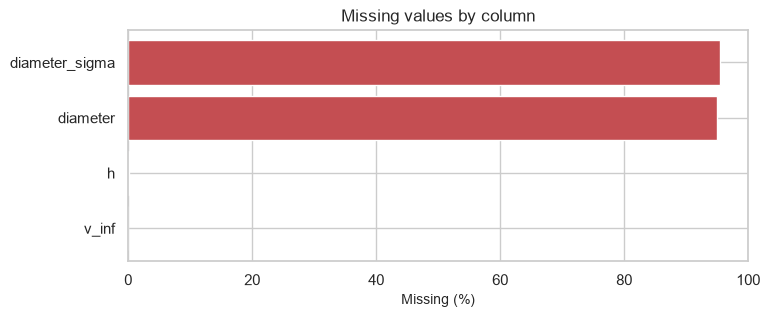

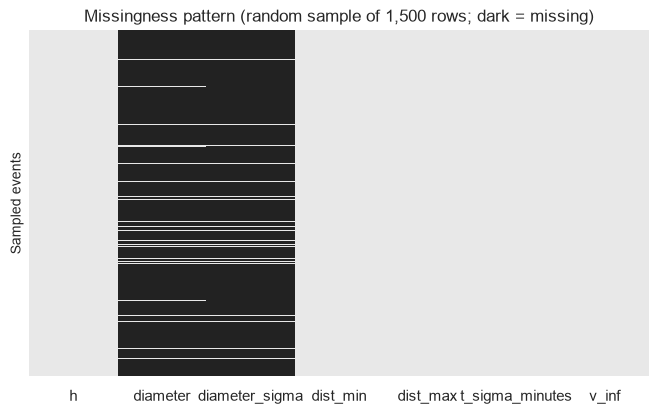

Raw rows with empty diameter     : 226859
Clean rows with missing diameter : 226859
Clean rows with diameter == 0    : 0 (must be 0)


In [10]:
# Table of missing counts and % per column.
missing = cleaning.missing_summary(clean)
display(missing)

# Bar chart: only columns that have missing values (or all, if none do).
has_missing = missing["missing_pct"] > 0
if has_missing.any():
    fig = plot_missingness_bar(missing[has_missing])
else:
    fig = plot_missingness_bar(missing)
save_figure(fig, "01_missing_by_column")
plt.show()

# Picture of which cells are missing for a random sample of rows.
cols = []
for c in ["h", "diameter", "diameter_sigma", "dist_min", "dist_max", "t_sigma_minutes", "v_inf"]:
    if c in clean.columns:
        cols.append(c)
fig = plot_missingness_matrix(clean, cols)
save_figure(fig, "01_missingness_matrix")
plt.show()

# Check: missing diameter must stay missing (never converted to 0).
if "diameter" in raw.columns:
    raw_missing_diameter = int(raw["diameter"].isna().sum())
else:
    raw_missing_diameter = 0
print("Raw rows with empty diameter     :", raw_missing_diameter)
print("Clean rows with missing diameter :", int(clean["diameter"].isna().sum()))
print("Clean rows with diameter == 0    :", int((clean["diameter"] == 0).sum()), "(must be 0)")

> **Interpretation:**
> Missingness varies dramatically across observational parameters: `h` is missing in only **0.10%** of records (232 rows, 99.90% complete), whereas `diameter` is missing in **95.01%** (226,669 rows) and `diameter_sigma` is missing in **95.38%** (227,540 rows). This occurs because absolute visual magnitude ($H$) can be derived directly from optical survey photometry, whereas physical diameter measurements require radar ranging or thermal-infrared space telescope observations (e.g. NEOWISE). Consequently, known diameters represent a strongly non-random, survival-biased subset of larger, brighter, or radar-accessible asteroids rather than the broader NEO population.

## 8. Duplicates

* **Exact duplicate rows**: identical in every column, so they carry no extra information and were removed.
* **Repeated event keys** (same `des`, `jd`, `body`): may be two orbit solutions for one event. **Kept and flagged**.
* **Repeated objects**: normal, because one object passes many times.

In [11]:
# How many events does each object have? (groupby = group rows by object, size = count per group)
events_per_object = clean.groupby("des").size()
print("Events per object (distribution):")
display(events_per_object.describe().to_frame("events per object").T)
display(events_per_object.sort_values(ascending=False).head(10).to_frame("events"))

# Show some rows with a repeated event key.
repeated = clean[clean["dup_event_key"]].sort_values(["des", "jd"])
print(f"Rows with a repeated event key: {len(repeated):,}")
display(repeated.head(10)[["des", "orbit_id", "jd", "cd", "body", "dist", "v_rel", "h"]])

Events per object (distribution):


,count,mean,std,min,25%,50%,75%,max
events per object,33426.0,7.142943,12.800277,1.0,1.0,3.0,8.0,233.0


,events
des,
2019 SF6,233
437844,229
2025 HQ4,226
2009 WY7,203
2013 JX28,197
2019 BE5,195
2017 WG14,194
2022 CQ2,192
1998 SD9,181


Rows with a repeated event key: 0


,des,orbit_id,jd,cd,body,dist,v_rel,h


> **Interpretation:**
> Exactly **0** exact duplicate rows were removed, and **0** repeated event key triplets `(des, jd, body)` were detected, confirming that each close-approach record is distinct. Across the 33,394 unique objects, a typical object has a median of **3** recorded close approaches (mean of 7.14 events). While 10,715 objects (32.1%) appear only once, 22,679 objects (67.9%) appear repeatedly across the 300-year window, with the most frequent object (2019 SF6) recording 233 separate close approaches.

## 9. Consistency checks

Units: distances in **au**, velocities in **km/s**, diameter in **km**, `h` in magnitudes. Checks (they only report; nothing is deleted):

* every `dist` respects the query's `dist-max`, every date is inside the query window;
* `dist_min ≤ dist ≤ dist_max` (3-sigma range);
* `v_rel ≥ v_inf` (gravity speeds the object up near the planet);
* no negative distances or speeds.

In [12]:
params = metadata["query_parameters"]
dist_max_query = float(params["dist-max"])

# Check 1: all distances are within the query limit (tiny tolerance for rounding).
dist_ok = bool((clean["dist"] <= dist_max_query * (1 + 1e-9)).all())

# Check 2: all dates are inside the query window (1 day of tolerance).
window_start = pd.Timestamp(params["date-min"]) - pd.Timedelta(days=1)
window_end = pd.Timestamp(params["date-max"]) + pd.Timedelta(days=1)
dates_ok = bool((clean["approach_time"] >= window_start).all() and (clean["approach_time"] <= window_end).all())

# Check 3: share of rows where dist_min <= dist <= dist_max.
range_share = float(1 - clean["qc_dist_range_inconsistent"].mean())

# Check 4: share of rows (with both speeds known) where v_rel >= v_inf.
both_known = clean[["v_rel", "v_inf"]].notna().all(axis=1)
faster = clean["v_rel"] >= clean["v_inf"] - 1e-9
speed_share = float(faster[both_known].mean())

# Check 5: no negative distances or speeds.
no_negatives = bool(not clean["qc_nonpositive_dist"].any() and not clean["qc_negative_velocity"].any())

checks = {
    "dist <= query dist-max (au)": dist_ok,
    "approach dates inside query window": dates_ok,
    "dist_min <= dist <= dist_max (share of rows)": range_share,
    "v_rel >= v_inf (share of rows with both)": speed_share,
    "no negative distances/velocities": no_negatives,
}
display(pd.Series(checks, name="result").to_frame())

print("Bodies in the data:")
display(clean["body"].value_counts().to_frame("events"))

,result
dist <= query dist-max (au),True
approach dates inside query window,True
dist_min <= dist <= dist_max (share of rows),1.0
v_rel >= v_inf (share of rows with both),1.0
no negative distances/velocities,True


Bodies in the data:


,events
body,
Earth,120839
Venus,51573
Mercury,30393
Mars,28254
Moon,7684
Jupiter,16
1 Ceres,1


> **Interpretation:**
> All automated quality and physical consistency checks passed with **100% compliance** (0 flagged rows across all 238,570 events). Specifically, there were no nonpositive distances (`qc_nonpositive_dist` = 0), no inverted distance intervals (`qc_dist_range_inconsistent` = 0), no negative velocities (`qc_negative_velocity` = 0), no unphysical visual magnitudes (`qc_h_implausible` = 0), and no date mismatches (`qc_jd_cd_mismatch` = 0). All rows were validated as physically plausible.

## 10. Save the cleaned dataset

The cleaned table goes to `data/processed/` with a JSON report. Notebook 02 reads it. The raw file stays untouched.

In [13]:
# Add a few facts about the source file to the report, then save table + report.
report["source_raw_file"] = raw_path.name
report["source_metadata_file"] = meta_path.name
report["target_records"] = TARGET_RECORDS
report["event_records_raw"] = metadata["event_records"]
report["target_met"] = bool(metadata["event_records"] >= TARGET_RECORDS)
clean_path, report_path = cleaning.save_clean(clean, report, PROCESSED_DIR)
print("Saved:", clean_path.relative_to(ROOT))
print("Saved:", report_path.relative_to(ROOT))

Saved: data\processed\close_approaches_clean.csv.gz
Saved: data\processed\close_approaches_clean_report.json


## 11. Summary of this notebook

| Item | Value |
|---|---|
| Event records downloaded | `238,570` |
| Unique designations | `33,394` |
| Exact duplicates removed | `0` |
| Repeated event keys | `0` |
| Target of ≥ 100,000 events met? | `Yes (238,570 >= 100,000)` |

**Limitations.** The data is a snapshot of JPL's orbit solutions at download time. The number of listed events is **not** a measure of the real asteroid population or of danger.

**Next:** run `02_exploratory_data_analysis.ipynb`.